# Lab 4: Classification and Evaluation in NLP
## Use case: Sentiment analysis of Amazon reviews of unlocked phones

Dataset: `Amazon_Unlocked_Mobile.csv` (Kaggle: PromptCloudHQ/amazon-reviews-unlocked-mobile-phones).
If this file is not next to the notebook, it falls back to the Apple tweets dataset (3 sentiment classes) so that it still runs.

In [1]:
import os
import re
from functools import lru_cache

import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

True

## Task 1: Load the data and do 5 preprocessing steps

In [2]:
def load_data():
    for path in ['Amazon_Unlocked_Mobile.csv', '/content/Amazon_Unlocked_Mobile.csv']:
        if os.path.exists(path):
            df = pd.read_csv(path)[['Reviews', 'Rating']].rename(columns={'Reviews': 'Review'})
            # rating -> sentiment: >3 positive, <3 negative, 3 neutral
            df['Sentiment'] = df['Rating'].map(
                lambda r: None if pd.isna(r) else ('positive' if r > 3 else ('negative' if r < 3 else 'neutral')))
            return df[['Review', 'Sentiment']], 'Amazon_Unlocked_Mobile.csv'
    df = pd.read_csv('apple-twitter-sentiment-texts.csv', encoding='utf-8-sig').rename(columns={'text': 'Review'})
    df['Sentiment'] = df['sentiment'].map({-1: 'negative', 0: 'neutral', 1: 'positive'})
    return df[['Review', 'Sentiment']], 'STAND-IN dataset: apple-twitter-sentiment-texts.csv (Amazon file not found)'

data, source = load_data()
print('Data source:', source)
print('Shape      :', data.shape)
data.head()

Data source: STAND-IN dataset: apple-twitter-sentiment-texts.csv (Amazon file not found)
Shape      : (1630, 2)


,Review,Sentiment
0,Wow. Yall needa step it up @Apple RT @heynyla:...,negative
1,What Happened To Apple Inc? http://t.co/FJEX...,neutral
2,Thank u @apple I can now compile all of the pi...,positive
3,The oddly uplifting story of the Apple co-foun...,neutral
4,@apple can i exchange my iphone for a differen...,neutral


In [3]:
data['Raw'] = data['Review']

# Step 1: remove missing values and duplicate reviews
data = data.dropna(subset=['Review', 'Sentiment']).drop_duplicates(subset='Review').copy()

# Step 2: lower casing
data['Review'] = data['Review'].str.lower()

# Step 3: remove URLs, HTML tags, punctuation, digits and special characters
data['Review'] = (data['Review']
                  .str.replace(r'https?://\S+|www\.\S+|<[^>]+>', ' ', regex=True)
                  .str.replace("'", '', regex=False)
                  .str.replace(r'[^a-z\s]', ' ', regex=True)
                  .str.replace(r'\s+', ' ', regex=True)
                  .str.strip())

# Step 4: remove stop words (negations such as "not", "no", "dont" are kept: they carry sentiment)
stop = {w.replace("'", '') for w in stopwords.words('english')}
stop -= {'no', 'nor', 'not'} | {w for w in stop if w.endswith('nt')}
data['Review'] = data['Review'].apply(lambda t: ' '.join(w for w in t.split() if w not in stop))

# Step 5: lemmatization
lemmatizer = WordNetLemmatizer()
lemma = lru_cache(maxsize=None)(lemmatizer.lemmatize)
data['Review'] = data['Review'].apply(lambda t: ' '.join(lemma(w) for w in t.split()))

# reviews that became empty after cleaning are removed
data = data[data['Review'].str.len() > 0]

for raw, clean in data[['Raw', 'Review']].head(3).values:
    print('BEFORE:', ' '.join(raw.split()))
    print('AFTER :', clean)
    print()
print('Shape after preprocessing:', data.shape)
print(data['Sentiment'].value_counts())

BEFORE: Wow. Yall needa step it up @Apple RT @heynyla: Music and snapchat at the same damn time. Thank you #Note4
AFTER : wow yall needa step apple rt heynyla music snapchat damn time thank note

BEFORE: What Happened To Apple Inc? http://t.co/FJEXI3oP0U #aapl #apple @MoneyPress http://t.co/wXKmmTMArW
AFTER : happened apple inc aapl apple moneypress

BEFORE: Thank u @apple I can now compile all of the pics that i communicate with in one place http://t.co/tq1lo09oyA
AFTER : thank u apple compile pic communicate one place

Shape after preprocessing: (1624, 3)
Sentiment
neutral     798
negative    683
positive    143
Name: count, dtype: int64


## Task 2: Train / test split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    data['Review'], data['Sentiment'],
    test_size=0.2, random_state=42, stratify=data['Sentiment'])   # stratify keeps the class proportions

print('Train size:', X_train.shape)
print('Test size :', X_test.shape)
print()
print(pd.DataFrame({'train': y_train.value_counts(normalize=True),
                    'test': y_test.value_counts(normalize=True)}).round(3))

Train size: (1299,)
Test size : (325,)

           train   test
Sentiment              
neutral    0.491  0.492
negative   0.420  0.422
positive   0.089  0.086


## Task 3: Feature extraction using TF-IDF

In [5]:
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train)   # fit on the training set only
X_test_tfidf = tfidf.transform(X_test)

print('Train matrix:', X_train_tfidf.shape)
print('Test matrix :', X_test_tfidf.shape)
print('Example features:', list(tfidf.get_feature_names_out()[:15]))

Train matrix: (1299, 5000)
Test matrix : (325, 5000)
Example features: ['aapl', 'aapl aapl', 'aapl apple', 'aapl brief', 'aapl buy', 'aapl buzz', 'aapl companytagged', 'aapl corporate', 'aapl corrupt', 'aapl coverage', 'aapl crus', 'aapl discussbrooklyn', 'aapl dont', 'aapl ebay', 'aapl expected']


## Task 4: Train a Naive Bayes classifier

In [6]:
nb = MultinomialNB()
nb.fit(X_train_tfidf, y_train)

print(nb)
print('Classes:', nb.classes_.tolist())

MultinomialNB()
Classes: ['negative', 'neutral', 'positive']


## Task 5: Evaluate the model on the test set

In [7]:
y_pred = nb.predict(X_test_tfidf)

print(f'Accuracy: {accuracy_score(y_test, y_pred):.4f}')
print()
print('Classification Report:')
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.7938

Classification Report:
              precision    recall  f1-score   support

    negative       0.79      0.88      0.83       137
     neutral       0.80      0.86      0.83       160
    positive       1.00      0.04      0.07        28

    accuracy                           0.79       325
   macro avg       0.86      0.59      0.57       325
weighted avg       0.81      0.79      0.76       325



## Task 6: Confusion matrix

               pred negative  pred neutral  pred positive
true negative            120            17              0
true neutral              23           137              0
true positive              9            18              1


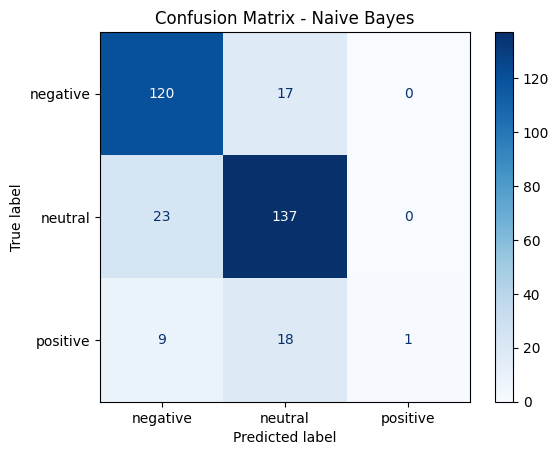

In [8]:
labels = ['negative', 'neutral', 'positive']
cm = confusion_matrix(y_test, y_pred, labels=labels)

print(pd.DataFrame(cm, index=[f'true {l}' for l in labels], columns=[f'pred {l}' for l in labels]))

ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap='Blues')
plt.title('Confusion Matrix - Naive Bayes')
plt.show()